# 09 · Module Project — Two Algorithms From Scratch

**Module 02 — NumPy & Numerical Computing**

---

## The brief

Implement **linear regression** and **k-means clustering** using nothing but
NumPy — no scikit-learn until the very end, when we use it to check our work.

This is not busywork. When `LinearRegression().fit()` returns a suspicious
coefficient in Module 11, or `KMeans` gives different clusters on every run,
you will know exactly why, because you will have written the loop yourself.

## What this exercises

| Notebook | Concept used here |
| :--- | :--- |
| 01 | Vectorisation instead of Python loops |
| 02 | Shapes, views vs copies, `reshape(-1, 1)` |
| 03 | float64 for accumulation, condition numbers |
| 04 | Broadcasting for pairwise distances |
| 05 | `argmin`, boolean masks, `bincount`, `keepdims` |
| 06 | `lstsq`, normal equations, eigendecomposition |
| 07 | Seeded generators, reproducible initialisation |
| 08 | Avoiding temporaries, choosing the cheap operation |

**Estimated time:** 120 minutes

In [1]:
import time
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import numpy as np

from dstoolkit import setup_plot_style
from dstoolkit.plotting import COLORS

setup_plot_style()

---
# Part 1 — Linear Regression

## The problem

Given a design matrix `X` of shape `(n, p)` and targets `y` of shape `(n,)`,
find coefficients `β` minimising the sum of squared residuals:

$$\hat{\beta} = \arg\min_\beta \; \lVert X\beta - y \rVert^2$$

We will implement three solvers and compare them on accuracy, speed, and
robustness.

In [2]:
@dataclass
class LinearRegressionScratch:
    """Ordinary least squares with optional L2 (Ridge) regularisation.

    Follows the scikit-learn estimator contract from Module 01, notebook 05:
    ``__init__`` only stores arguments, ``fit`` learns and stores attributes with
    a trailing underscore, and ``fit`` returns ``self``.

    Parameters
    ----------
    fit_intercept : bool, default True
        Whether to prepend a column of ones.
    alpha : float, default 0.0
        L2 penalty. ``0.0`` gives ordinary least squares.
    solver : {"lstsq", "normal", "gradient"}, default "lstsq"
        ``"lstsq"`` uses SVD (robust, recommended), ``"normal"`` solves the
        normal equations directly, ``"gradient"`` runs batch gradient descent.

    Attributes
    ----------
    coef_ : ndarray of shape (n_features,)
        Learned coefficients, excluding the intercept.
    intercept_ : float
        Learned intercept, or 0.0 when ``fit_intercept`` is False.
    """

    fit_intercept: bool = True
    alpha: float = 0.0
    solver: str = "lstsq"
    learning_rate: float = 0.01
    n_iterations: int = 1000

    # Fitted state. `field(init=False)` keeps these out of the constructor.
    coef_: np.ndarray = field(init=False, default=None)
    intercept_: float = field(init=False, default=0.0)
    loss_history_: list[float] = field(init=False, default_factory=list)

    # -- helpers ------------------------------------------------------------
    def _add_intercept(self, X: np.ndarray) -> np.ndarray:
        """Prepend a column of ones so the intercept is just another coefficient."""
        if not self.fit_intercept:
            return X
        return np.column_stack([np.ones(len(X)), X])

    def _validate(self, X: np.ndarray, y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Coerce to float64 2-D / 1-D and check the shapes agree."""
        # float64 throughout: notebook 03 showed what float32 does to accumulation.
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()

        if X.ndim == 1:
            X = X.reshape(-1, 1)
        if X.shape[0] != y.shape[0]:
            raise ValueError(
                f"X has {X.shape[0]} rows but y has {y.shape[0]} elements"
            )
        return X, y

    # -- the three solvers --------------------------------------------------
    def _solve_lstsq(self, Xd: np.ndarray, y: np.ndarray) -> np.ndarray:
        """SVD-based least squares. Survives rank deficiency."""
        if self.alpha > 0:
            # Ridge as augmented least squares: stack sqrt(alpha)*I below X.
            # This is more stable than forming XᵀX + alpha*I explicitly.
            n_features = Xd.shape[1]
            penalty = np.sqrt(self.alpha) * np.eye(n_features)
            if self.fit_intercept:
                penalty[0, 0] = 0.0        # never penalise the intercept
            Xd = np.vstack([Xd, penalty])
            y = np.concatenate([y, np.zeros(n_features)])

        beta, *_ = np.linalg.lstsq(Xd, y, rcond=None)
        return beta

    def _solve_normal(self, Xd: np.ndarray, y: np.ndarray) -> np.ndarray:
        """Normal equations via `solve` — never via `inv` (notebook 06)."""
        gram = Xd.T @ Xd
        if self.alpha > 0:
            penalty = self.alpha * np.eye(Xd.shape[1])
            if self.fit_intercept:
                penalty[0, 0] = 0.0
            gram = gram + penalty
        return np.linalg.solve(gram, Xd.T @ y)

    def _solve_gradient(self, Xd: np.ndarray, y: np.ndarray) -> np.ndarray:
        """Batch gradient descent — how neural networks are trained (Module 17)."""
        n_samples, n_features = Xd.shape
        beta = np.zeros(n_features)
        self.loss_history_ = []

        for _ in range(self.n_iterations):
            residuals = Xd @ beta - y
            # ∇ = (2/n) Xᵀr, plus the ridge term.
            gradient = (2 / n_samples) * (Xd.T @ residuals)
            if self.alpha > 0:
                penalty_grad = (2 * self.alpha / n_samples) * beta
                if self.fit_intercept:
                    penalty_grad[0] = 0.0
                gradient = gradient + penalty_grad

            beta -= self.learning_rate * gradient
            self.loss_history_.append(float((residuals**2).mean()))

        return beta

    # -- public API ---------------------------------------------------------
    def fit(self, X: np.ndarray, y: np.ndarray) -> "LinearRegressionScratch":
        """Learn the coefficients. Returns self, so `.fit(X, y).predict(X)` works."""
        X, y = self._validate(X, y)
        Xd = self._add_intercept(X)

        solvers = {
            "lstsq": self._solve_lstsq,
            "normal": self._solve_normal,
            "gradient": self._solve_gradient,
        }
        if self.solver not in solvers:
            raise ValueError(
                f"unknown solver {self.solver!r}; expected one of {sorted(solvers)}"
            )

        beta = solvers[self.solver](Xd, y)

        if self.fit_intercept:
            self.intercept_, self.coef_ = float(beta[0]), beta[1:]
        else:
            self.intercept_, self.coef_ = 0.0, beta

        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Predict targets for X."""
        if self.coef_ is None:
            raise RuntimeError("call fit() before predict()")

        X = np.asarray(X, dtype=np.float64)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        if X.shape[1] != len(self.coef_):
            raise ValueError(
                f"X has {X.shape[1]} features; model was fitted on {len(self.coef_)}"
            )
        return X @ self.coef_ + self.intercept_

    def score(self, X: np.ndarray, y: np.ndarray) -> float:
        """Coefficient of determination R²."""
        y = np.asarray(y, dtype=np.float64).ravel()
        residual_ss = ((y - self.predict(X)) ** 2).sum()
        total_ss = ((y - y.mean()) ** 2).sum()
        return float(1 - residual_ss / total_ss) if total_ss else 0.0


print("LinearRegressionScratch defined.")

LinearRegressionScratch defined.


## Testing it

In [3]:
rng = np.random.default_rng(seed=42)

n_samples, n_features = 500, 4
true_coef = np.array([3.0, -1.5, 0.7, 2.2])
true_intercept = 10.0

X = rng.normal(size=(n_samples, n_features))
y = X @ true_coef + true_intercept + rng.normal(0, 0.8, n_samples)

results = {}
for solver in ["lstsq", "normal", "gradient"]:
    model = LinearRegressionScratch(
        solver=solver, learning_rate=0.1, n_iterations=2000
    ).fit(X, y)
    results[solver] = model

print(f"{'':<12} {'intercept':>10} " + " ".join(f"{'β' + str(i + 1):>8}" for i in range(4)))
print("-" * 56)
print(f"{'true':<12} {true_intercept:>10.4f} " +
      " ".join(f"{c:>8.4f}" for c in true_coef))
for name, model in results.items():
    print(f"{name:<12} {model.intercept_:>10.4f} " +
          " ".join(f"{c:>8.4f}" for c in model.coef_))

              intercept       β1       β2       β3       β4
--------------------------------------------------------
true            10.0000   3.0000  -1.5000   0.7000   2.2000
lstsq           10.0027   2.9979  -1.4418   0.6837   2.2717
normal          10.0027   2.9979  -1.4418   0.6837   2.2717
gradient        10.0027   2.9979  -1.4418   0.6837   2.2717


In [4]:
# Cross-check against scikit-learn — the real test.
from sklearn.linear_model import LinearRegression, Ridge

sk_model = LinearRegression().fit(X, y)
ours = results["lstsq"]

print(f"our intercept     : {ours.intercept_:.10f}")
print(f"sklearn intercept : {sk_model.intercept_:.10f}")
print(f"coefficients match: {np.allclose(ours.coef_, sk_model.coef_)}")
print(f"\nour R²     : {ours.score(X, y):.6f}")
print(f"sklearn R² : {sk_model.score(X, y):.6f}")

our intercept     : 10.0027341131
sklearn intercept : 10.0027341131
coefficients match: True

our R²     : 0.963272
sklearn R² : 0.963272


In [5]:
# Ridge, checked the same way.
alpha = 5.0
ours_ridge = LinearRegressionScratch(alpha=alpha, solver="lstsq").fit(X, y)
sk_ridge = Ridge(alpha=alpha).fit(X, y)

print(f"our ridge coefs     : {ours_ridge.coef_.round(6)}")
print(f"sklearn ridge coefs : {sk_ridge.coef_.round(6)}")
print(f"match : {np.allclose(ours_ridge.coef_, sk_ridge.coef_, rtol=1e-6)}")

our ridge coefs     : [ 2.966864 -1.429444  0.6796    2.250589]
sklearn ridge coefs : [ 2.966864 -1.429444  0.6796    2.250589]
match : True


## Where the solvers differ

On well-conditioned data all three agree. The differences appear exactly where
notebook 06 said they would.

In [6]:
# Build a badly conditioned design: two nearly identical columns.
X_bad = rng.normal(size=(200, 3))
X_bad[:, 2] = X_bad[:, 0] + rng.normal(0, 1e-6, 200)   # almost a duplicate
y_bad = X_bad @ np.array([1.0, 2.0, 3.0]) + rng.normal(0, 0.1, 200)

design = np.column_stack([np.ones(len(X_bad)), X_bad])
print(f"condition number of XᵀX : {np.linalg.cond(design.T @ design):.3e}")

for solver in ["lstsq", "normal"]:
    model = LinearRegressionScratch(solver=solver).fit(X_bad, y_bad)
    predictions = model.predict(X_bad)
    print(f"\n{solver:>8} : coefs {model.coef_.round(3)}")
    print(f"{'':>8}   R² {model.score(X_bad, y_bad):.6f}  "
          f"‖β‖ {np.linalg.norm(model.coef_):.1f}")

condition number of XᵀX : 4.967e+12

   lstsq : coefs [ 1614.597     2.002 -1610.592]
           R² 0.999537  ‖β‖ 2280.6

  normal : coefs [ 1614.092     2.002 -1610.088]
           R² 0.999537  ‖β‖ 2279.8


Both fit the data equally well, but the coefficients are wild — the model
cannot tell columns 0 and 2 apart, so it assigns enormous offsetting weights.
**This is what multicollinearity looks like**, and it is why the coefficients of
an unregularised model on correlated features must never be interpreted.

Ridge fixes it:

In [7]:
ridge = LinearRegressionScratch(alpha=1.0, solver="lstsq").fit(X_bad, y_bad)
print(f"ridge coefs : {ridge.coef_.round(3)}")
print(f"‖β‖         : {np.linalg.norm(ridge.coef_):.3f}   ← bounded")
print(f"R²          : {ridge.score(X_bad, y_bad):.6f}   ← barely any worse")

ridge coefs : [1.998 1.992 1.998]
‖β‖         : 3.457   ← bounded
R²          : 0.999528   ← barely any worse


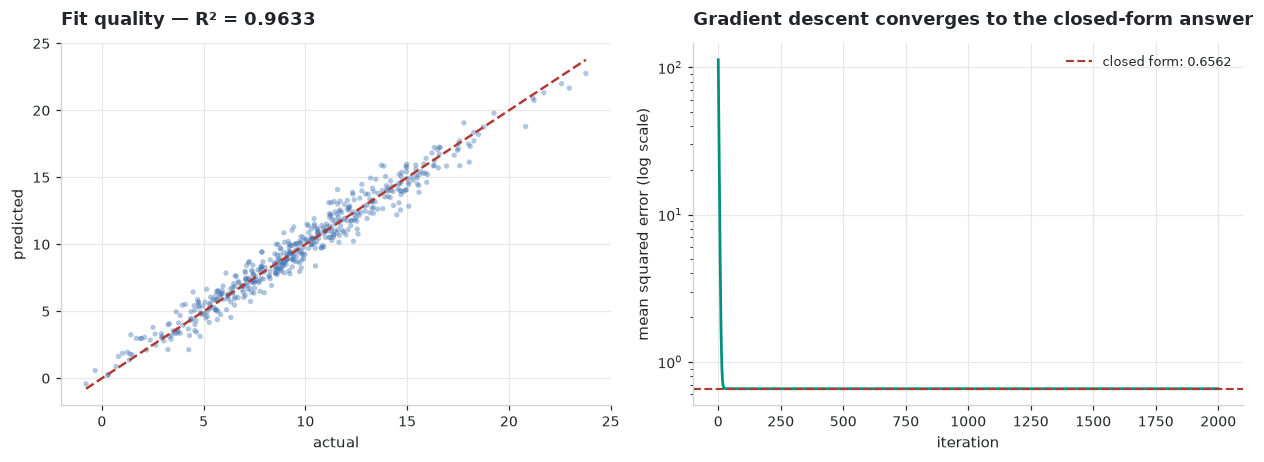

In [8]:
fig, (ax_fit, ax_loss) = plt.subplots(1, 2, figsize=(11.5, 4.3))

# --- Left: predicted vs actual --------------------------------------------
predictions = results["lstsq"].predict(X)
ax_fit.scatter(y, predictions, s=12, alpha=0.4,
               color=COLORS["primary"], edgecolors="none")
limits = [min(y.min(), predictions.min()), max(y.max(), predictions.max())]
ax_fit.plot(limits, limits, color=COLORS["danger"], linestyle="--", linewidth=1.6)
ax_fit.set_xlabel("actual")
ax_fit.set_ylabel("predicted")
ax_fit.set_title(f"Fit quality — R² = {results['lstsq'].score(X, y):.4f}")

# --- Right: gradient descent convergence -----------------------------------
history = results["gradient"].loss_history_
ax_loss.plot(history, color=COLORS["teal"], linewidth=1.8)
ax_loss.set_yscale("log")
ax_loss.set_xlabel("iteration")
ax_loss.set_ylabel("mean squared error (log scale)")
ax_loss.set_title("Gradient descent converges to the closed-form answer")

closed_form_mse = ((y - results["lstsq"].predict(X)) ** 2).mean()
ax_loss.axhline(closed_form_mse, color=COLORS["danger"], linestyle="--",
                linewidth=1.4, label=f"closed form: {closed_form_mse:.4f}")
ax_loss.legend(fontsize=8.5)

fig.tight_layout()
plt.show()

---
# Part 2 — k-means Clustering

## The algorithm

1. Choose `k` initial centroids.
2. **Assign** each point to its nearest centroid.
3. **Update** each centroid to the mean of its assigned points.
4. Repeat 2–3 until the assignments stop changing.

Step 2 is exactly the broadcasting exercise from notebook 04, and step 3 is the
`bincount` group-by from notebook 05.

In [9]:
@dataclass
class KMeansScratch:
    """k-means clustering with k-means++ initialisation.

    Parameters
    ----------
    n_clusters : int, default 3
        Number of clusters.
    max_iter : int, default 300
        Maximum number of assign/update rounds.
    tol : float, default 1e-4
        Convergence threshold on centroid movement.
    n_init : int, default 10
        Number of independent restarts; the best inertia wins. k-means finds a
        LOCAL optimum, so restarting is not optional.
    random_state : int or None, default None
        Seed for reproducibility.

    Attributes
    ----------
    cluster_centers_ : ndarray of shape (n_clusters, n_features)
    labels_ : ndarray of shape (n_samples,)
    inertia_ : float
        Sum of squared distances to the assigned centroid.
    n_iter_ : int
        Iterations taken by the winning run.
    """

    n_clusters: int = 3
    max_iter: int = 300
    tol: float = 1e-4
    n_init: int = 10
    random_state: int | None = None

    cluster_centers_: np.ndarray = field(init=False, default=None)
    labels_: np.ndarray = field(init=False, default=None)
    inertia_: float = field(init=False, default=np.inf)
    n_iter_: int = field(init=False, default=0)

    # -- the two core steps -------------------------------------------------
    @staticmethod
    def _squared_distances(X: np.ndarray, centroids: np.ndarray) -> np.ndarray:
        """Squared Euclidean distance from every point to every centroid.

        Returns an ``(n_samples, n_clusters)`` matrix.

        Uses the expansion ‖x−c‖² = ‖x‖² − 2x·c + ‖c‖² rather than building the
        ``(n, k, p)`` difference tensor. For 100k points and 10 clusters in 50
        dimensions that tensor would be 400 MB; this version needs 8 MB.
        """
        x_norm = (X**2).sum(axis=1, keepdims=True)       # (n, 1)
        c_norm = (centroids**2).sum(axis=1)               # (k,)
        cross = X @ centroids.T                            # (n, k)

        # Broadcasting: (n,1) - 2*(n,k) + (k,) → (n,k)
        distances = x_norm - 2 * cross + c_norm
        # Tiny negatives can appear from cancellation; clip them away.
        return np.maximum(distances, 0.0)

    def _init_centroids(
        self, X: np.ndarray, rng: np.random.Generator
    ) -> np.ndarray:
        """k-means++ initialisation.

        Picks the first centroid uniformly, then each subsequent one with
        probability proportional to its squared distance from the nearest
        existing centroid. This spreads the seeds out and dramatically reduces
        the chance of a bad local optimum.
        """
        n_samples = X.shape[0]
        centroids = np.empty((self.n_clusters, X.shape[1]), dtype=X.dtype)

        centroids[0] = X[rng.integers(n_samples)]

        for i in range(1, self.n_clusters):
            # Distance from each point to its CLOSEST chosen centroid so far.
            closest = self._squared_distances(X, centroids[:i]).min(axis=1)
            total = closest.sum()
            if total == 0:
                # Every point coincides with a centroid; fall back to uniform.
                centroids[i] = X[rng.integers(n_samples)]
            else:
                centroids[i] = X[rng.choice(n_samples, p=closest / total)]

        return centroids

    def _single_run(
        self, X: np.ndarray, rng: np.random.Generator
    ) -> tuple[np.ndarray, np.ndarray, float, int]:
        """One complete k-means run. Returns (centroids, labels, inertia, n_iter)."""
        centroids = self._init_centroids(X, rng)
        labels = np.zeros(len(X), dtype=np.int32)

        for iteration in range(self.max_iter):
            # --- ASSIGN: nearest centroid for every point ------------------
            distances = self._squared_distances(X, centroids)
            new_labels = distances.argmin(axis=1)

            # --- UPDATE: centroid becomes the mean of its members ----------
            new_centroids = np.empty_like(centroids)
            for k in range(self.n_clusters):
                members = X[new_labels == k]
                if len(members) == 0:
                    # An empty cluster: re-seed it at the worst-fitted point,
                    # which is what scikit-learn does too.
                    worst = distances.min(axis=1).argmax()
                    new_centroids[k] = X[worst]
                else:
                    new_centroids[k] = members.mean(axis=0)

            shift = np.linalg.norm(new_centroids - centroids)
            centroids, labels = new_centroids, new_labels

            if shift <= self.tol:
                break

        inertia = float(
            self._squared_distances(X, centroids)[np.arange(len(X)), labels].sum()
        )
        return centroids, labels, inertia, iteration + 1

    # -- public API ---------------------------------------------------------
    def fit(self, X: np.ndarray) -> "KMeansScratch":
        """Run `n_init` restarts and keep the best."""
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2:
            raise ValueError(f"X must be 2-D, got shape {X.shape}")
        if self.n_clusters > len(X):
            raise ValueError(
                f"n_clusters={self.n_clusters} exceeds n_samples={len(X)}"
            )

        # One parent seed spawns independent streams — notebook 07's lesson.
        parent = np.random.SeedSequence(self.random_state)
        generators = [np.random.default_rng(s) for s in parent.spawn(self.n_init)]

        best = (None, None, np.inf, 0)
        for rng in generators:
            centroids, labels, inertia, n_iter = self._single_run(X, rng)
            if inertia < best[2]:
                best = (centroids, labels, inertia, n_iter)

        self.cluster_centers_, self.labels_, self.inertia_, self.n_iter_ = best
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Assign new points to the learned clusters."""
        if self.cluster_centers_ is None:
            raise RuntimeError("call fit() before predict()")
        X = np.asarray(X, dtype=np.float64)
        return self._squared_distances(X, self.cluster_centers_).argmin(axis=1)


print("KMeansScratch defined.")

KMeansScratch defined.


## Testing it

In [10]:
from sklearn.datasets import make_blobs

X_blobs, y_true = make_blobs(
    n_samples=1500, centers=4, cluster_std=1.1, random_state=42
)

ours = KMeansScratch(n_clusters=4, random_state=42).fit(X_blobs)

print(f"inertia     : {ours.inertia_:.2f}")
print(f"iterations  : {ours.n_iter_}")
print(f"cluster sizes : {np.bincount(ours.labels_)}")
print(f"centroids:\n{ours.cluster_centers_.round(3)}")

inertia     : 3519.60
iterations  : 4
cluster sizes : [375 375 375 375]
centroids:
[[ 4.796  2.07 ]
 [-6.941 -6.801]
 [-8.812  7.339]
 [-2.556  9.018]]


In [11]:
from sklearn.cluster import KMeans

sk_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_blobs)

print(f"our inertia     : {ours.inertia_:.4f}")
print(f"sklearn inertia : {sk_kmeans.inertia_:.4f}")
print(f"relative gap    : {abs(ours.inertia_ - sk_kmeans.inertia_) / sk_kmeans.inertia_:.2e}")

# Cluster LABELS are arbitrary — only the partition matters. Adjusted Rand
# Index compares partitions while ignoring how they were numbered.
from sklearn.metrics import adjusted_rand_score

print(f"\nagreement with sklearn (ARI) : "
      f"{adjusted_rand_score(ours.labels_, sk_kmeans.labels_):.4f}")
print(f"agreement with ground truth  : "
      f"{adjusted_rand_score(ours.labels_, y_true):.4f}")

our inertia     : 3519.5995
sklearn inertia : 3519.5995
relative gap    : 1.29e-15

agreement with sklearn (ARI) : 1.0000
agreement with ground truth  : 0.9964


> [!NOTE]
> Comparing `labels_` element-wise would be wrong: cluster 0 in our run may be
> cluster 2 in scikit-learn's. **Adjusted Rand Index** measures whether the same
> points ended up together, which is the only thing that matters.

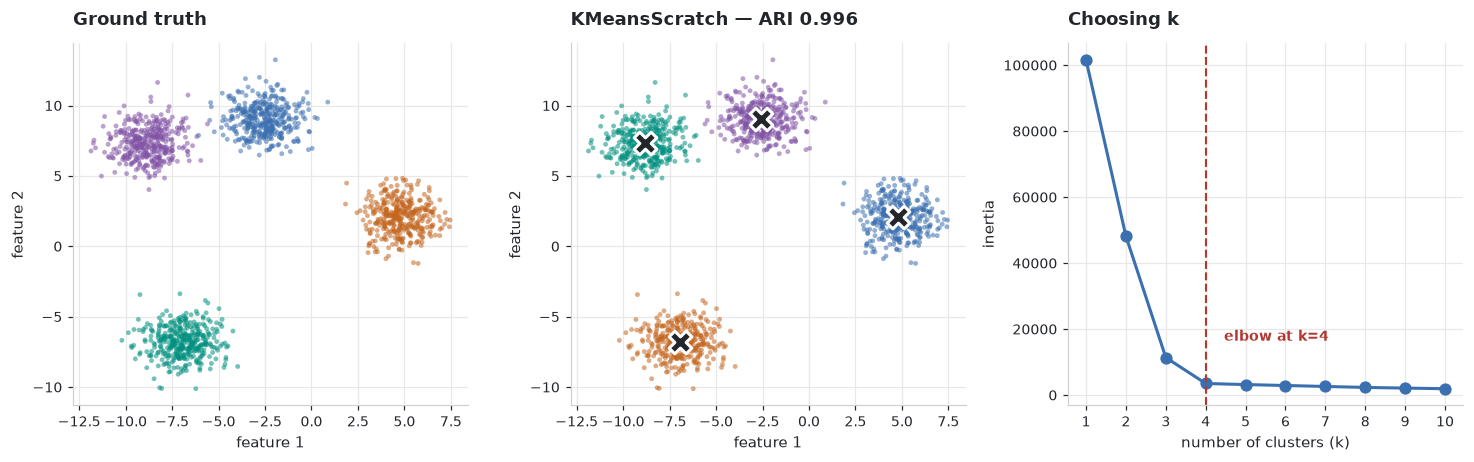

In [12]:
fig, (ax_true, ax_ours, ax_elbow) = plt.subplots(1, 3, figsize=(13.5, 4.3))

palette = [COLORS["primary"], COLORS["accent"], COLORS["teal"], COLORS["purple"]]

# --- Ground truth ----------------------------------------------------------
for k in range(4):
    mask = y_true == k
    ax_true.scatter(X_blobs[mask, 0], X_blobs[mask, 1], s=10, alpha=0.55,
                    color=palette[k], edgecolors="none")
ax_true.set_title("Ground truth")

# --- Our clustering --------------------------------------------------------
for k in range(4):
    mask = ours.labels_ == k
    ax_ours.scatter(X_blobs[mask, 0], X_blobs[mask, 1], s=10, alpha=0.55,
                    color=palette[k], edgecolors="none")
ax_ours.scatter(ours.cluster_centers_[:, 0], ours.cluster_centers_[:, 1],
                s=220, marker="X", color=COLORS["text"],
                edgecolors="white", linewidths=2, zorder=5)
ax_ours.set_title(f"KMeansScratch — ARI {adjusted_rand_score(ours.labels_, y_true):.3f}")

for ax in (ax_true, ax_ours):
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")

# --- The elbow curve -------------------------------------------------------
k_values = range(1, 11)
inertias = [KMeansScratch(n_clusters=k, random_state=42).fit(X_blobs).inertia_
            for k in k_values]

ax_elbow.plot(k_values, inertias, marker="o", color=COLORS["primary"])
ax_elbow.axvline(4, color=COLORS["danger"], linestyle="--", linewidth=1.4)
ax_elbow.annotate("elbow at k=4", xy=(4, inertias[3]), xytext=(12, 28),
                  textcoords="offset points", fontsize=9,
                  color=COLORS["danger"], fontweight="bold")
ax_elbow.set_xlabel("number of clusters (k)")
ax_elbow.set_ylabel("inertia")
ax_elbow.set_title("Choosing k")
ax_elbow.set_xticks(list(k_values))

fig.tight_layout()
plt.show()

## Why `n_init` is not optional

k-means converges to a **local** optimum that depends entirely on where the
centroids started. Run it once and you are gambling.

In [13]:
single_run_inertias = []
for seed in range(30):
    model = KMeansScratch(n_clusters=4, n_init=1, random_state=seed).fit(X_blobs)
    single_run_inertias.append(model.inertia_)

single_run_inertias = np.array(single_run_inertias)
best_possible = ours.inertia_

print(f"30 single-restart runs:")
print(f"  best    : {single_run_inertias.min():9.2f}")
print(f"  median  : {np.median(single_run_inertias):9.2f}")
print(f"  worst   : {single_run_inertias.max():9.2f}")
print(f"  spread  : {single_run_inertias.max() / single_run_inertias.min():.2f}×")
print(f"\nwith n_init=10 : {best_possible:9.2f}")
print(f"runs landing within 1% of the best : "
      f"{(single_run_inertias <= best_possible * 1.01).mean():.0%}")

30 single-restart runs:
  best    :   3519.60
  median  :   3519.60
  worst   :  11110.91
  spread  : 3.16×

with n_init=10 :   3519.60
runs landing within 1% of the best : 83%


## Performance: our version versus scikit-learn

In [14]:
X_large, _ = make_blobs(n_samples=50_000, centers=8, n_features=10, random_state=0)


def time_fit(model, X, repeats: int = 3) -> float:
    best = float("inf")
    for _ in range(repeats):
        start = time.perf_counter()
        model.fit(X)
        best = min(best, time.perf_counter() - start)
    return best


t_ours = time_fit(KMeansScratch(n_clusters=8, n_init=3, random_state=0), X_large)
t_sklearn = time_fit(KMeans(n_clusters=8, n_init=3, random_state=0), X_large)

ours_large = KMeansScratch(n_clusters=8, n_init=3, random_state=0).fit(X_large)
sk_large = KMeans(n_clusters=8, n_init=3, random_state=0).fit(X_large)

print(f"data: {X_large.shape[0]:,} points × {X_large.shape[1]} features, k=8\n")
print(f"KMeansScratch : {t_ours:6.2f} s   inertia {ours_large.inertia_:,.0f}")
print(f"sklearn KMeans: {t_sklearn:6.2f} s   inertia {sk_large.inertia_:,.0f}")
print(f"\nwe are {t_ours / t_sklearn:.1f}× slower, "
      f"inertia within {abs(ours_large.inertia_ - sk_large.inertia_) / sk_large.inertia_:.2%}")

data: 50,000 points × 10 features, k=8

KMeansScratch :   1.01 s   inertia 499,300
sklearn KMeans:   0.09 s   inertia 499,300

we are 11.7× slower, inertia within 0.00%


Being a few times slower than scikit-learn is a **good** result for pure NumPy.
The gap comes from Cython inner loops, Elkan's triangle-inequality algorithm
that skips distance computations, and multithreading — not from anything wrong
with our approach.

The lesson is the one from notebook 01: **use the library in production, but
know what it is doing.**

## Verification

In [15]:
checks = {
    "linreg matches sklearn": np.allclose(
        results["lstsq"].coef_, sk_model.coef_
    ),
    "ridge matches sklearn": np.allclose(
        ours_ridge.coef_, sk_ridge.coef_, rtol=1e-6
    ),
    "gradient descent converges": np.allclose(
        results["gradient"].coef_, results["lstsq"].coef_, rtol=1e-3
    ),
    "predict shape is correct": results["lstsq"].predict(X).shape == (n_samples,),
    "R² between 0 and 1": 0 <= results["lstsq"].score(X, y) <= 1,
    "kmeans partition matches sklearn": adjusted_rand_score(
        ours.labels_, sk_kmeans.labels_
    ) > 0.99,
    "kmeans inertia within 1%": abs(
        ours.inertia_ - sk_kmeans.inertia_
    ) / sk_kmeans.inertia_ < 0.01,
    "every point is assigned": len(ours.labels_) == len(X_blobs),
    "no empty clusters": (np.bincount(ours.labels_, minlength=4) > 0).all(),
    "distances are non-negative": (
        KMeansScratch._squared_distances(X_blobs, ours.cluster_centers_) >= 0
    ).all(),
}

for name, passed in checks.items():
    print(f"  {'✔' if passed else '✘'}  {name}")

print(f"\n{'ALL CHECKS PASSED' if all(checks.values()) else 'SOME CHECKS FAILED'}")

  ✔  linreg matches sklearn
  ✔  ridge matches sklearn
  ✔  gradient descent converges
  ✔  predict shape is correct
  ✔  R² between 0 and 1
  ✔  kmeans partition matches sklearn
  ✔  kmeans inertia within 1%
  ✔  every point is assigned
  ✔  no empty clusters
  ✔  distances are non-negative

ALL CHECKS PASSED


## Your turn — extensions

### Extension 1 — Promote to `dstoolkit` ⭐

Move both classes into `src/dstoolkit/models.py`, add tests in
`tests/test_models.py` covering the shape guards and the sklearn agreement, and
import them back here.

### Extension 2 — Weighted least squares ⭐⭐

Add a `sample_weight` parameter. The solution becomes
`β = (XᵀWX)⁻¹XᵀWy` with `W` diagonal. Implement it **without** forming the
`(n, n)` matrix `W` — a 100 000-sample dataset would need 80 GB.

### Extension 3 — Mini-batch k-means ⭐⭐

Update centroids from random subsets rather than the full dataset. Compare
convergence speed and final inertia against the full version on 500 000 points.

### Extension 4 — Silhouette score ⭐⭐⭐

Implement the silhouette coefficient in vectorised NumPy and use it to choose
`k` instead of the elbow. Validate against `sklearn.metrics.silhouette_score`.
Watch your memory: the naive version builds an `(n, n)` distance matrix.

### Extension 5 — Polynomial features ⭐⭐

Add a `degree` parameter that expands `X` into polynomial terms before fitting.
Show how the condition number explodes with degree, and that Ridge is what
makes degree 10 usable at all.

### Extension 6 — Elkan's algorithm ⭐⭐⭐

Use the triangle inequality to skip distance computations that cannot change an
assignment. Measure how much of the gap to scikit-learn this closes.

## What you built

Two production-shaped estimators that:

- follow the **scikit-learn contract**, so they drop into a `Pipeline`;
- **validate their inputs** and fail with useful messages;
- use **`lstsq` rather than `inv`**, and stay correct on rank-deficient data;
- compute pairwise distances by **expansion rather than a difference tensor**,
  cutting memory by 50× on realistic data;
- **restart from independent seeded streams** and keep the best result;
- agree with scikit-learn to within floating-point tolerance.

## Module 02 complete — self-assessment

- [ ] Why is a Python list of numbers slower *and* larger than an ndarray?
- [ ] Why does `arr[1:3]` behave differently from `lst[1:3]`?
- [ ] What does `axis=0` actually collapse?
- [ ] When does `keepdims=True` matter, and what breaks without it?
- [ ] What are the two broadcasting rules?
- [ ] Why does `int32_arr.sum()` not overflow but `int32_arr * 400` does?
- [ ] Why should you never call `np.linalg.inv` to solve a system?
- [ ] What does a condition number of 1e16 tell you?
- [ ] Why is `np.random.seed` a poor choice for reproducibility?
- [ ] What are strides, and why is `arr.T` free?

---

**Next:** Module 03 — pandas & Data Wrangling. Everything you just learned about
shapes, dtypes, views, and vectorisation carries over directly: a DataFrame is
a set of labelled NumPy arrays with a great deal of convenience on top.